# Lecture 4: Household savings

The fourth model lets households save. They keep a fixed share of disposable income as saving and spend the rest. The economy is still closed and has no investment, so the only agent that can use household saving is the government, which now runs a deficit. A new equation makes saving and the public balance add up, and the government's spending adjusts to keep it that way.

:::{admonition} Watch the lectures
:class: tip

- 📺 Lecture: [Computable General Equilibrium model: households' savings](https://www.youtube.com/watch?v=nXbQxzzDQno)
- ✅ Correction: [Computable General Equilibrium model with households' savings: Correction](https://www.youtube.com/watch?v=5zP_4FOlDSI)
- 🎓 Full course playlist: [Antoine Bouet's CGE lectures](https://www.youtube.com/playlist?list=PLfV47vAW_jrc57x1O36Pz9vol86f0YUXW)
:::

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cge_modeling as cm

## The economy

Production, prices and the government's revenue are unchanged from the third notebook. Two things change on the spending side:

- Households save a fixed share $mps$ of disposable income, $savings = mps \cdot DISP\_INC$, and spend the rest on goods with the same Cobb-Douglas shares as before.
- The government no longer has to balance its budget. Its public balance $pubsold$ (the course's *solde public*) is revenue minus spending, and it is negative when the government runs a deficit.

An agent that saves needs another agent that borrows. With no investment and no rest of the world, the government is the only candidate. The economy-wide balance is therefore $savings + pubsold = 0$: household saving finances the public deficit exactly.

### Variables

Two variables are new, household saving and the public balance.

In [2]:
sectors = ["Agr", "Ind", "Serv"]
mod = cm.CGEModel(coords={"i": sectors, "j": sectors})

with mod:
    Y = cm.Variable("Y", dims="i", description="Output of sector <dim:i>")
    VA = cm.Variable("VA", dims="i", description="Value added in sector <dim:i>")
    IC = cm.Variable("IC", dims="i", description="Intermediate bundle used by sector <dim:i>")
    CIJ = cm.Variable("CIJ", dims=("i", "j"), description="Good <dim:i> used by sector <dim:j>")
    KD = cm.Variable("KD", dims="i", description="Capital demand of sector <dim:i>")
    LD = cm.Variable("LD", dims="i", description="Labor demand of sector <dim:i>")
    P = cm.Variable("P", dims="i", description="Consumer price of good <dim:i>")
    PY = cm.Variable("PY", dims="i", description="Producer price of good <dim:i>")
    PVA = cm.Variable("PVA", dims="i", description="Price of value added in sector <dim:i>")
    PIC = cm.Variable("PIC", dims="i", description="Price of the intermediate bundle in sector <dim:i>")
    W = cm.Variable("W", description="Wage")
    R = cm.Variable("R", description="Return to capital")
    INC = cm.Variable("INC", description="Gross income of households")
    DISP_INC = cm.Variable("DISP_INC",
                           latex_name=r"\mathrm{DISP\_INC}",
                           description="Disposable income of households")
    savings = cm.Variable("savings", description="Household saving")
    C = cm.Variable("C", dims="i", description="Household consumption of good <dim:i>")
    U = cm.Variable("U", description="Utility of households")
    BUDG_EXP = cm.Variable("BUDG_EXP",
                           latex_name=r"\mathrm{BUDG\_EXP}",
                           description="Government spending")
    pubsold = cm.Variable("pubsold", description="Public balance, revenue minus spending")
    CG = cm.Variable("CG", dims="i", description="Government purchases of good <dim:i>")
    Leon = cm.Variable("Leon", description="Walras check variable")

mod.summary("variables")

<IPython.core.display.Latex object>

### Parameters

The marginal propensity to save $mps$ is the only new parameter.

In [3]:
with mod:
    alpha = cm.Parameter("alpha", dims="i", description="Capital share of value added in sector <dim:i>")
    A = cm.Parameter("A", dims="i", description="Productivity in sector <dim:i>")
    psi_VA = cm.Parameter("psi_VA", dims="i", description="Value added per unit of output in sector <dim:i>")
    psi_IC = cm.Parameter("psi_IC", dims="i", description="Intermediate bundle per unit of output in sector <dim:i>")
    psi_IJC = cm.Parameter("psi_IJC",
                           dims=("i", "j"),
                           description="Good <dim:i> per unit of the intermediate bundle of sector <dim:j>")
    gamma = cm.Parameter("gamma", dims="i", description="Household budget share of good <dim:i>")
    alpha_g = cm.Parameter("alpha_g",
                           dims="i",
                           latex_name=r"\alpha^G",
                           description="Government budget share of good <dim:i>")
    mps = cm.Parameter("mps", description="Marginal propensity to save")
    itr = cm.Parameter("itr", description="Income tax rate")
    tau = cm.Parameter("tau", dims="i", description="Indirect tax rate on good <dim:i>")
    LS = cm.Parameter("LS", description="Labor supply")
    KS = cm.Parameter("KS", description="Capital supply")
    P_Agr = cm.Parameter("P_Agr", latex_name=r"\bar{P}_{Agr}", description="Price of agriculture, the numeraire")

mod.summary("parameters")

<IPython.core.display.Latex object>

### Equations

Three equations change from the third notebook. Households spend $(1 - mps) \cdot DISP\_INC$ on goods. The government budget now defines the public balance as revenue minus spending, instead of setting spending equal to revenue. The labor market clears exactly, without $Leon$.

Two equations are new. The saving equation fixes saving as a share of disposable income. The macroeconomic balance adds saving and the public balance, and $Leon$ moves there from the labor market.

The lecture discusses both placements of $Leon$. In the labor market, with the macroeconomic balance imposed exactly, it would check the same thing: all equations but one imply the last. The course puts it in the macroeconomic balance, and so does this notebook.

In [4]:
with mod:
    cm.Equation("Tax wedge", PY * (1 + tau), P)
    cm.Equation("Value added demand", VA, psi_VA * Y)
    cm.Equation("Intermediate bundle demand", IC, psi_IC * Y)
    cm.Equation("Zero profit", PY * Y, PVA * VA + PIC * IC)
    cm.Equation("Value added production", VA, A * KD**alpha * LD ** (1 - alpha))
    cm.Equation("Capital demand", R * KD, alpha * PVA * VA)
    cm.Equation("Labor demand", W * LD, (1 - alpha) * PVA * VA)
    cm.Equation("Intermediate bundle price", (PIC * IC).rename(i="j"), (P * CIJ).sum("i"))
    cm.Equation("Intermediate input demand", CIJ, psi_IJC * IC.rename(i="j"))
    cm.Equation("Income", INC, W * LS + R * KS)
    cm.Equation("Disposable income", DISP_INC, (1 - itr) * INC)
    cm.Equation("Saving", savings, mps * DISP_INC)
    cm.Equation("Consumption", P * C, gamma * (1 - mps) * DISP_INC)
    cm.Equation("Utility", U, (C**gamma).prod())
    cm.Equation("Public balance", pubsold, itr * INC + (tau * PY * Y).sum() - BUDG_EXP)
    cm.Equation("Government demand", P * CG, alpha_g * BUDG_EXP)
    cm.Equation("Labor market clearing", LS, LD.sum())
    cm.Equation("Capital market clearing", KS, KD.sum())
    cm.Equation("Goods market clearing", Y, C + CG + CIJ.sum("j"))
    cm.Equation("Macroeconomic balance", savings + pubsold, Leon)
    cm.Equation("Numeraire", P.sel(i="Agr"), P_Agr)

mod.equation_table()

<IPython.core.display.Latex object>

In [5]:
mod.compile();

Compiling a model with 51 equations, 51 variables, 35 parameters


The model has 51 equations in 51 variables. The course fixes $P_{Agr}$ directly and reports 50 equations in 50 free variables, the same system.

## Data

The SAM differs from the third notebook's in two places. Households pay 3000 in income tax instead of 3700, and a new row `Solde` records each agent's net lending. Households save 700. The government spends 4200 against revenue of 3500, so its entry is a deficit of -700. The `Solde` row sums to zero, which is the macroeconomic balance in the data. Factor payments, goods flows and household consumption are unchanged.

In [6]:
accounts = ["LD", "KD", "Hld", "Gvt", *sectors, "Solde"]
sam = pd.DataFrame(0.0, index=accounts, columns=accounts)
sam.loc["LD", sectors] = [1300.0, 1900.0, 4000.0]
sam.loc["KD", sectors] = [200.0, 2100.0, 500.0]
sam.loc["Hld", ["LD", "KD"]] = [7200.0, 2800.0]
sam.loc["Gvt", ["Hld", *sectors]] = [3000.0, 100.0, 220.0, 180.0]
sam.loc[sectors, "Hld"] = [1700.0, 1200.0, 3400.0]
sam.loc[sectors, "Gvt"] = [400.0, 1500.0, 2300.0]
sam.loc[sectors, sectors] = [[1000.0, 1000.0, 1000.0],
                             [2010.0, 3510.0, 3000.0],
                             [490.0, 2490.0, 1000.0]]
sam.loc["Solde", ["Hld", "Gvt"]] = [700.0, -700.0]

assert np.allclose(sam.sum(axis=0), sam.sum(axis=1))
sam

,LD,KD,Hld,Gvt,Agr,Ind,Serv,Solde
LD,0.0,0.0,0.0,0.0,1300.0,1900.0,4000.0,0.0
KD,0.0,0.0,0.0,0.0,200.0,2100.0,500.0,0.0
Hld,7200.0,2800.0,0.0,0.0,0.0,0.0,0.0,0.0
Gvt,0.0,0.0,3000.0,0.0,100.0,220.0,180.0,0.0
Agr,0.0,0.0,1700.0,400.0,1000.0,1000.0,1000.0,0.0
Ind,0.0,0.0,1200.0,1500.0,2010.0,3510.0,3000.0,0.0
Serv,0.0,0.0,3400.0,2300.0,490.0,2490.0,1000.0,0.0
Solde,0.0,0.0,700.0,-700.0,0.0,0.0,0.0,0.0


## Calibration

The calibration follows the third notebook, with producer prices normalized to 1 and quantities of goods divided by the consumer price $P_{0,i} = 1 + \tau_i$. Saving and the public balance come straight from the `Solde` row. The saving rate is saving over disposable income, and the household budget shares are now shares of consumption spending $(1 - mps) \cdot DISP\_INC$.

In [7]:
def calibrate_model(mod, sam):
    LD = sam.loc["LD", sectors].values
    KD = sam.loc["KD", sectors].values
    CIJ = sam.loc[sectors, sectors].values
    C = sam.loc[sectors, "Hld"].values
    CG = sam.loc[sectors, "Gvt"].values
    INDTAX = sam.loc["Gvt", sectors].values
    DIRTAX = sam.loc["Gvt", "Hld"]
    savings = sam.loc["Solde", "Hld"]
    pubsold = sam.loc["Solde", "Gvt"]

    PY = np.ones(len(sectors))
    PVA = np.ones(len(sectors))
    PIC = np.ones(len(sectors))
    W = 1.0
    R = 1.0

    output_value = LD + KD + CIJ.sum(axis=0) + INDTAX
    tau = INDTAX / (output_value - INDTAX)
    P = PY * (1 + tau)

    CIJ = CIJ / P[:, None]
    C = C / P
    CG = CG / P
    Y = output_value / P

    LS = LD.sum()
    KS = KD.sum()
    VA = (W * LD + R * KD) / PVA
    alpha = R * KD / (PVA * VA)
    A = VA / (KD**alpha * LD ** (1 - alpha))
    IC = (P[:, None] * CIJ).sum(axis=0) / PIC

    psi_VA = VA / Y
    psi_IC = IC / Y
    psi_IJC = CIJ / IC[None, :]

    INC = W * LS + R * KS
    itr = DIRTAX / INC
    DISP_INC = (1 - itr) * INC
    mps = savings / DISP_INC
    gamma = P * C / ((1 - mps) * DISP_INC)
    U = np.prod(C**gamma)
    BUDG_EXP = (P * CG).sum()
    alpha_g = P * CG / BUDG_EXP

    Leon = savings + pubsold
    P_Agr = P[sectors.index("Agr")]

    return mod.finalize_calibration()


calibrated_values = calibrate_model(mod, sam)

In [8]:
pd.Series({name: float(calibrated_values[name])
           for name in ["INC", "itr", "DISP_INC", "mps", "savings", "BUDG_EXP", "pubsold"]}).round(4)

INC         10000.0
itr             0.3
DISP_INC     7000.0
mps             0.1
savings       700.0
BUDG_EXP     4200.0
pubsold      -700.0
dtype: float64

In [9]:
mod.check_for_equilibrium(calibrated_values)

Equilibrium found! Total squared error: 0.000000


## Cutting the income tax rate

The lecture's exercise asks for two shocks, a 10% increase in labor supply and a 10% cut in the indirect tax rates. The correction solves neither. It cuts the income tax rate by 5%, from 0.30 to 0.285, and this section reproduces that experiment first.

In [10]:
tax_cut = mod.simulate(initial_state=calibrated_values,
                       final_delta_pct={"itr": 0.95})
assert tax_cut["optim_res"].success

Progress               Elapsed   Residual     ||Jᵀf||      Step         
 ──────────────────────────────────────────────────────────────────────────────────────── 
  Euler           ━━━━━━━━━━━━━━━━━━━━   0:00:02   0.00000130   0.00121557   10000/10000  
  Finding Roots   ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000004       3/    3

The correction reports:

| | Agr | Ind | Serv |
|---|---|---|---|
| $Y$ growth (%) | 0.528 | -0.161 | -0.033 |
| $C$ growth (%) | 2.142 | 2.161 | 2.135 |
| $P$ growth (%) | 0 | -0.018 | 0.007 |

and growth of 0.042% in the wage, -0.111% in the return to capital and $-5.8 \times 10^{-4}$% in income, with a Fisher consumer price index of 1.000. As in the third notebook, the functions below report the index times 100.

In [11]:
def growth(result, name):
    variables = result["optimizer"]["variables"]
    initial = variables[name].isel(step=0).values
    final = variables[name].isel(step=-1).values
    return 100 * (final / initial - 1)


def sector_growth(result, names):
    return pd.DataFrame({f"{name} growth (%)": growth(result, name) for name in names},
                        index=sectors).T


def aggregate_growth(result):
    variables = result["optimizer"]["variables"]
    benchmark_prices = variables["P"].isel(step=0).values
    benchmark_consumption = variables["C"].isel(step=0).values
    prices = variables["P"].isel(step=-1).values
    consumption = variables["C"].isel(step=-1).values

    laspeyres = (prices * benchmark_consumption).sum() / (benchmark_prices * benchmark_consumption).sum()
    paasche = (prices * consumption).sum() / (benchmark_prices * consumption).sum()

    return pd.Series({"W growth (%)": growth(result, "W"),
                      "R growth (%)": growth(result, "R"),
                      "INC growth (%)": growth(result, "INC"),
                      "PIndC": 100 * np.sqrt(laspeyres * paasche)})


sector_growth(tax_cut, names=["Y", "C", "P"]).round(3)

,Agr,Ind,Serv
Y growth (%),0.528,-0.161,-0.033
C growth (%),2.142,2.161,2.135
P growth (%),0.000,-0.018,0.007


In [12]:
aggregate_growth(tax_cut).round(4)

W growth (%)        0.0425
R growth (%)       -0.1113
INC growth (%)     -0.0006
PIndC             100.0004
dtype: float64

In [13]:
float(tax_cut["optimizer"]["variables"]["Leon"].isel(step=-1))

-6.62656324909031e-13

Every number matches the correction, and $Leon$ is zero up to floating-point error.

The correction's listing does not show how the income flows adjust. The table below follows the tax cut from revenue to spending. Tax revenue is the government's spending plus its balance.

In [14]:
def income_flows(state):
    return pd.Series({"disposable income": float(state["DISP_INC"]),
                      "household consumption spending": float((state["P"] * state["C"]).sum()),
                      "household saving": float(state["savings"]),
                      "tax revenue": float(state["BUDG_EXP"] + state["pubsold"]),
                      "government spending": float(state["BUDG_EXP"]),
                      "public balance": float(state["pubsold"])})


tax_cut_variables = tax_cut["optimizer"]["variables"]
flows = pd.DataFrame({"benchmark": income_flows(tax_cut_variables.isel(step=0)),
                      "itr = 0.285": income_flows(tax_cut_variables.isel(step=-1))})
flows["change"] = flows["itr = 0.285"] - flows["benchmark"]
flows.round(1)

,benchmark,itr = 0.285,change
disposable income,7000.0,7150.0,150.0
household consumption spending,6300.0,6435.0,135.0
household saving,700.0,715.0,15.0
tax revenue,3500.0,3350.1,-149.9
government spending,4200.0,4065.1,-134.9
public balance,-700.0,-715.0,-15.0


The tax cut raises disposable income by 150. Households spend 90% of it and save 10%, so saving rises by 15. The government loses 150 of revenue but can borrow only what households save, so its deficit widens by 15 and its spending falls by 135. The sector effects follow the same pattern as in the third notebook. Households buy more agriculture and the government buys less industry, so agricultural output rises and industrial output falls.

## The lecture's shocks

The lecture asks for a 10% increase in labor supply and a 10% cut in all three indirect tax rates. Neither video solves them, so the tables below are new results from the same model.

In [15]:
lecture_shocks = {"LS +10%": mod.simulate(initial_state=calibrated_values,
                                          final_delta_pct={"LS": 1.1},
                                          progressbar=False),
                  "tau x 0.9": mod.simulate(initial_state=calibrated_values,
                                            final_delta_pct={"tau": 0.9},
                                            progressbar=False)}
assert all(result["optim_res"].success for result in lecture_shocks.values())

pd.concat({label: sector_growth(result, names=["Y", "C", "P"]) for label, result in lecture_shocks.items()},
          axis=1).round(3)

LS +10%               tau x 0.9              
                 Agr    Ind   Serv       Agr    Ind   Serv
Y growth (%)   7.101  6.728  7.398     0.154 -0.028 -0.026
C growth (%)   7.129  5.683  7.700     0.560  0.518  0.454
P growth (%)   0.000  1.368 -0.530     0.000  0.042  0.105

In [16]:
def shock_summary(result):
    flows = income_flows(result["optimizer"]["variables"].isel(step=-1))
    return pd.concat([aggregate_growth(result),
                      flows[["household saving", "government spending"]]])


pd.DataFrame({label: shock_summary(result) for label, result in lecture_shocks.items()}).round(3)

,LS +10%,tau x 0.9
W growth (%),-3.163,0.567
R growth (%),8.695,0.542
INC growth (%),7.129,0.560
PIndC,99.972,100.065
household saving,749.905,703.921
government spending,4501.192,4171.890


More labor raises income by 7.1%. Saving, tax revenue and therefore government spending all grow with it, so the government's spending rises to about 4501. Prices move as in the second notebook: labor gets cheaper relative to capital, so the labor-intensive services sector gets cheaper and industry gets more expensive.

The indirect tax cut is small. Agriculture's consumer price is the numeraire, so a lower tax rate on agriculture raises its producer price, and nominal factor prices and income rise with it, by about 0.56%. Government spending falls by about 28, the lost indirect tax revenue net of the extra income tax and saving.

## Choosing the closure

The macroeconomic balance adds one equation, so one more variable has to adjust to satisfy it. The course lets government spending adjust and holds the saving rate fixed. That is a modeling choice, and the opposite choice is just as consistent: hold government spending at its benchmark and let the saving rate adjust, so that households save whatever the government needs to borrow.

The two closures share every equation and differ only in which object is a variable. `copy` makes an independent copy of the model, and `reassign_roles` turns `BUDG_EXP` into a parameter and `mps` into a variable on the copy.

In [17]:
fixed_spending = mod.copy().reassign_roles(to_parameters="BUDG_EXP", to_variables="mps").compile()

Compiling a model with 51 equations, 51 variables, 35 parameters


In [18]:
fixed_spending_cut = fixed_spending.simulate(initial_state=calibrated_values,
                                            final_delta_pct={"itr": 0.95})
assert fixed_spending_cut["optim_res"].success

Progress               Elapsed   Residual     ||Jᵀf||      Step         
 ──────────────────────────────────────────────────────────────────────────────────────── 
  Euler           ━━━━━━━━━━━━━━━━━━━━   0:00:02   0.00033515   2.88472636   10000/10000  
  Finding Roots   ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000000       3/    3

In [19]:
def model_state(result, step):
    node = result["optimizer"].isel(step=step)
    return {**node["variables"].data_vars, **node["parameters"].data_vars}


def closure_summary(result):
    benchmark = model_state(result, step=0)
    final = model_state(result, step=-1)
    summary = (income_flows(final) - income_flows(benchmark)).add_prefix("change in ")
    summary["saving rate after the cut"] = float(final["mps"])
    return summary


closures = {"spending adjusts": tax_cut, "saving rate adjusts": fixed_spending_cut}
pd.DataFrame({label: closure_summary(result) for label, result in closures.items()}).round(3)

,spending adjusts,saving rate adjusts
change in disposable income,149.958,150.000
change in household consumption spending,134.963,0.000
change in household saving,14.996,150.000
change in tax revenue,-149.929,-150.000
change in government spending,-134.933,0.000
change in public balance,-14.996,-150.000
saving rate after the cut,0.100,0.119


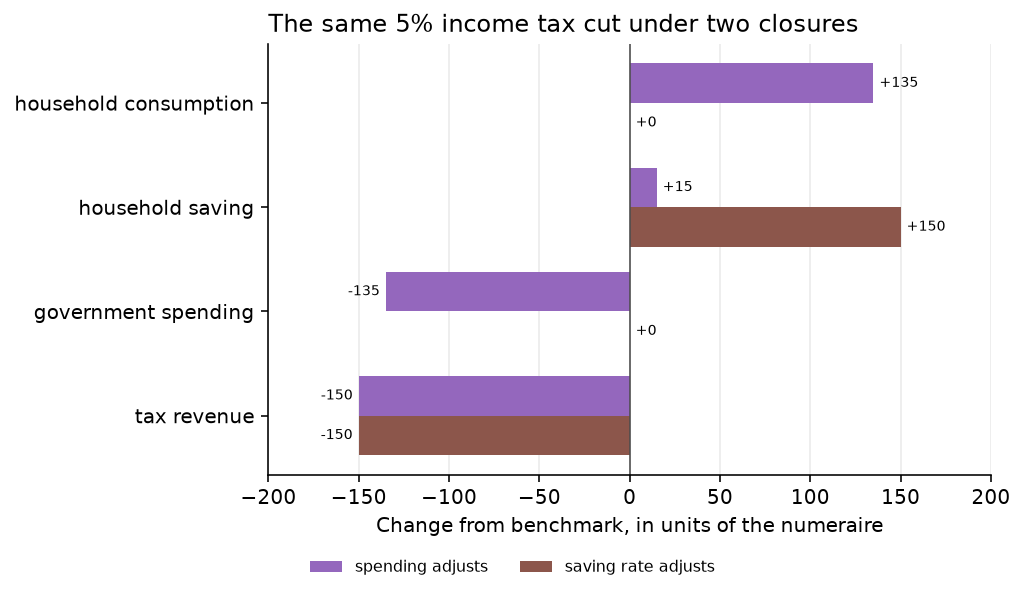

In [20]:
flows_to_plot = {"change in household consumption spending": "household consumption",
                 "change in household saving": "household saving",
                 "change in government spending": "government spending",
                 "change in tax revenue": "tax revenue"}
closure_colors = {"spending adjusts": "C4", "saving rate adjusts": "C5"}
positions = np.arange(len(flows_to_plot))
bar_height = 0.38

fig, ax = plt.subplots(figsize=(7, 4),
                       dpi=144,
                       layout="constrained")
for offset, (label, result) in zip([-bar_height / 2, bar_height / 2], closures.items()):
    changes = closure_summary(result)[list(flows_to_plot)]
    bars = ax.barh(positions + offset,
                   changes.values,
                   height=bar_height,
                   color=closure_colors[label],
                   label=label)
    ax.bar_label(bars,
                 fmt="%+.0f",
                 fontsize=7,
                 padding=3)

ax.axvline(0.0,
           color="0.3",
           linewidth=0.8)
ax.set_yticks(positions,
              labels=list(flows_to_plot.values()))
ax.invert_yaxis()
ax.set_xlim(-200, 200)
ax.set_xlabel("Change from benchmark, in units of the numeraire")
ax.set_title("The same 5% income tax cut under two closures",
             loc="left")
ax.grid(axis="x",
        color="0.92")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="outside lower center",
           ncol=len(labels),
           frameon=False,
           fontsize=8)
plt.show()

Disposable income and tax revenue move by 150 in both closures, but the money goes to different places. When government spending adjusts, households spend 90% of the cut and save the other 15, the government can borrow only those 15, and spending moves from the government to households. When the saving rate adjusts, the government keeps spending 4200 and borrows the whole 150, so households must save all of it. Their saving rate rises from 0.100 to 0.119, consumption does not change, and no sector's output moves. The equations and the shock are the same in both runs, so the difference comes entirely from which variable absorbs the macroeconomic balance.

## Leon catches a data error

$Leon$ has been zero in every experiment so far. To see what it catches, the cell below repeats the calibration with one typo in the SAM: households buy 3300 of services instead of 3400. The household column no longer adds up to the household row, and the calibrated budget shares $\gamma_i$ sum to less than one, so households leave part of their consumption budget unspent.

In [21]:
typo_sam = sam.copy()
typo_sam.loc["Serv", "Hld"] = 3300.0
typo_values = calibrate_model(mod, typo_sam)

float(typo_values["gamma"].sum())

0.9841269841269842

In [22]:
mod.check_for_equilibrium(typo_values)

Equilibrium not found. Total squared error: 9631.556929


Equation                                            Residual
Goods market clearing [i=Serv]                       98.140496


The benchmark check already fails. The services market misses clearing by about 98, the missing 100 of spending measured in volume at the consumer price. A model whose benchmark fails this check should not be simulated. If it is solved anyway, the solver finds an equilibrium of the faulty model, and $Leon$ measures the size of the error.

In [23]:
typo_cut = mod.simulate(initial_state=typo_values,
                        final_delta_pct={"itr": 0.95},
                        progressbar=False)
assert typo_cut["optim_res"].success

typo_state = model_state(typo_cut, step=-1)
unspent_income = (1 - typo_state["gamma"].sum()) * (1 - typo_state["mps"]) * typo_state["DISP_INC"]
pd.Series({"Leon": float(typo_state["Leon"]),
           "unspent household income": float(unspent_income)}).round(3)

Leon                       -102.144
unspent household income    102.144
dtype: float64

$Leon$ is minus the household income that consumption no longer spends. No market buys the goods that income would have bought, so saving and the public deficit no longer match, and the gap appears in the macroeconomic balance. With a correct SAM, the same simulation gives $Leon$ of order $10^{-13}$.

The next lecture adds investment demand, which gives household saving a second use and replaces the government as the only borrower.

## Authors

- Created by Jesse Grabowski, November 25, 2026

## Watermark

In [24]:
%load_ext watermark
%watermark -n -u -v -iv -m -w

Last updated: Thu, 26 Nov 2026

Python implementation: CPython
Python version       : 3.12.13
IPython version      : 9.18.1

Compiler    : Clang 19.1.7 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

cge_modeling: 0.0.7.dev15+g93cb61e4e.d20261120
matplotlib  : 3.11.2
numpy       : 2.3.5
pandas      : 3.1.1

Watermark: 2.6.0

